<a href="https://colab.research.google.com/github/fathinahnj/ggf-guava-spots-project/blob/main/detect_guava_spots.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
!pip install -q ultralytics opencv-python-headless ipywidgets

In [18]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="SlBxRabVfF2QYLeZwq44")
project = rf.workspace("fathinahs-workspace").project("guava-seg-hwznh")
version = project.version(1)
dataset = version.download("yolo26")

loading Roboflow workspace...
loading Roboflow project...


In [22]:
from google.colab import files
import os
import zipfile
import glob

BASE_DIR = "/content/drive/MyDrive/ggf_guava_project"

FRAME_DIR = project.search(
    limit=10,
    in_dataset=True,
)

SEG_MODEL_PATH = os.path.join(BASE_DIR, 'weights.pt')
TRACK_MODEL_PATH = os.path.join(BASE_DIR, 'tracking_guava_seg_model.pt')

TRACKER_CONFIG = "bytetrack.yaml"

TRACK_CLASS_ID = None

OUTPUT_DIR = "/content/drive/MyDrive/guava_project/output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [26]:
segmentation_model = YOLO(SEG_MODEL_PATH)
tracking_model = YOLO(TRACK_MODEL_PATH)

In [23]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob
import os

from ultralytics import YOLO

# Load model
model = YOLO(SEG_MODEL_PATH)

search_path = os.path.join(dataset.location, '**/*.jpg')
image_paths = glob.glob(search_path, recursive=True)

# Urutkan berdasarkan nama file
image_paths = sorted(image_paths)[:10]

if len(image_paths) == 0:
    raise FileNotFoundError(f"Tidak ada gambar yang ditemukan di {dataset.location}.")

print(f"Jumlah frame yang akan diproses: {len(image_paths)}")

for path in image_paths:
    print(os.path.basename(path))

Jumlah frame yang akan diproses: 10
20261117_20261117115107_20261117115714_115106_mp4-0009_jpg.rf.b7428bc48d247c9da1e4036de53df9c3.jpg
20261117_20261117115107_20261117115714_115106_mp4-0040_jpg.rf.0704f8f0a6c9be1b02eeb15c1a131b6a.jpg
20261117_20261117115107_20261117115714_115106_mp4-0047_jpg.rf.f1d1cac4be03925734f76ba1e8c1b8f8.jpg
20261117_20261117115107_20261117115714_115106_mp4-0054_jpg.rf.7f9b044540c18a52a419e8470fc74d3d.jpg
20261117_20261117115107_20261117115714_115106_mp4-0073_jpg.rf.d4b3cd843fc65f3d17962ba39805260c.jpg
20261117_20261117115107_20261117115714_115106_mp4-0088_jpg.rf.13e2c7ae8c3f1c2ea2af5efff5053254.jpg
20261117_20261117115107_20261117115714_115106_mp4-0101_jpg.rf.e65dc41ffb99b0cf7a22f48d92278900.jpg
20261117_20261117115107_20261117115714_115106_mp4-0118_jpg.rf.40f66a7bde7ad1c76612446a4c7bf86f.jpg
20261117_20261117115107_20261117115714_115106_mp4-0124_jpg.rf.6ba3ca9fc8d27f3427535973055facb9.jpg
20261117_20261117115107_20261117115714_115106_mp4-0127_jpg.rf.5b5581654bb

In [24]:
import ipywidgets as widgets
from IPython.display import display

# Pengaturan threshold
h_max_slider = widgets.IntSlider(
    value=25, min=0, max=179,
    description="H max:",
    continuous_update=False
)

s_min_slider = widgets.IntSlider(
    value=0, min=0, max=255,
    description="S min:",
    continuous_update=False
)

v_max_slider = widgets.IntSlider(
    value=190, min=0, max=255,
    description="V max:",
    continuous_update=False
)

conf_slider = widgets.FloatSlider(
    value=0.50, min=0.10, max=0.95, step=0.05,
    description="Confidence:",
    continuous_update=False
)

display(h_max_slider, s_min_slider, v_max_slider, conf_slider)

IntSlider(value=25, continuous_update=False, description='H max:', max=179)

IntSlider(value=0, continuous_update=False, description='S min:', max=255)

IntSlider(value=190, continuous_update=False, description='V max:', max=255)

FloatSlider(value=0.5, continuous_update=False, description='Confidence:', max=0.95, min=0.1, step=0.05)

In [14]:
# Simpan hasil segmentasi buah agar tidak perlu inference ulang
frame_data = []

for image_path in image_paths:

    image = cv2.imread(image_path)

    if image is None:
        print(f"Gagal membaca: {image_path}")
        continue

    height, width = image.shape[:2]

    # Inference model segmentasi buah
    results = model.predict(
        source=image,
        conf=conf_slider.value,
        retina_masks=True,
        verbose=False
    )

    result = results[0]

    # Mask gabungan seluruh buah dalam frame
    fruit_mask = np.zeros((height, width), dtype=np.uint8)

    if result.masks is not None:
        masks = result.masks.data.cpu().numpy()

        for mask in masks:
            resized_mask = cv2.resize(
                mask,
                (width, height),
                interpolation=cv2.INTER_NEAREST
            )

            fruit_mask[resized_mask > 0.5] = 255

    frame_data.append({
        "path": image_path,
        "image": image,
        "fruit_mask": fruit_mask
    })

print(f"Segmentasi selesai: {len(frame_data)} frame.")

Segmentasi selesai: 10 frame.


Button(button_style='success', description='Tampilkan hasil', icon='play', style=ButtonStyle())

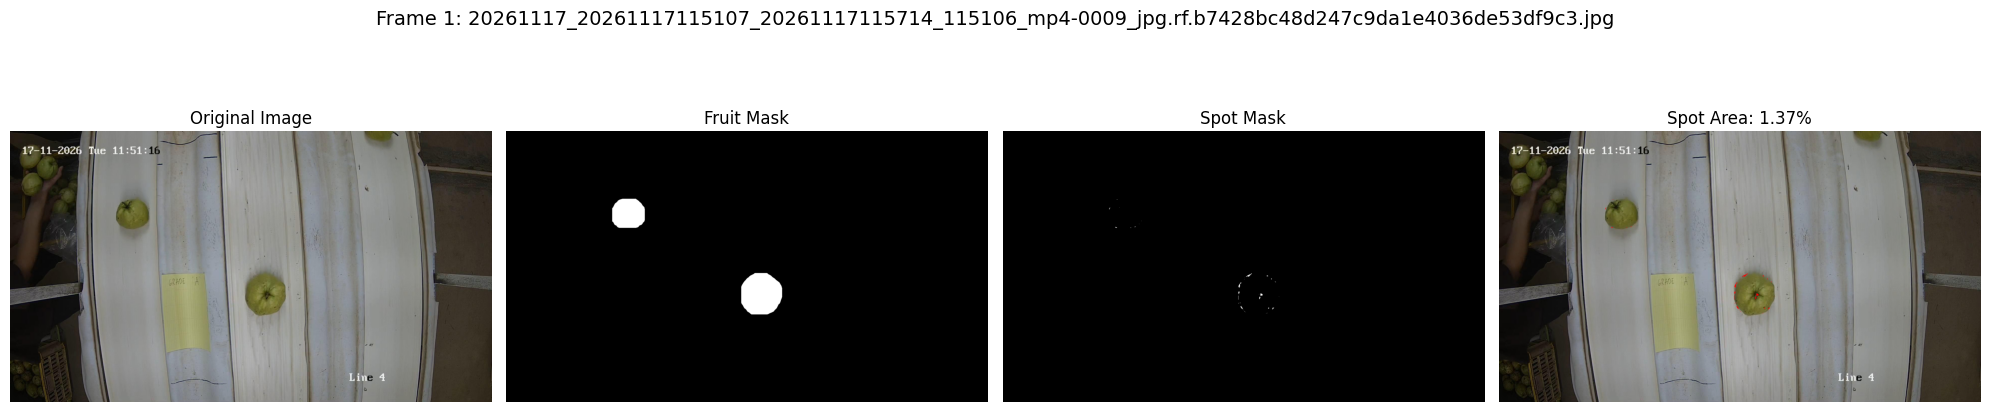

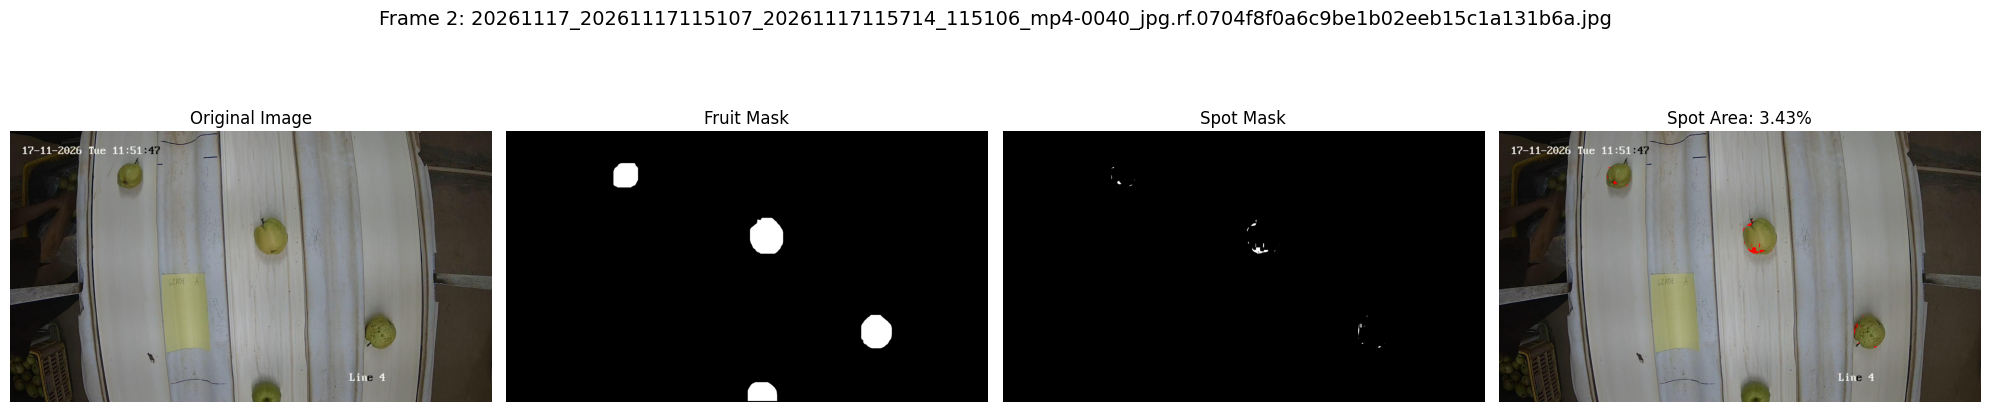

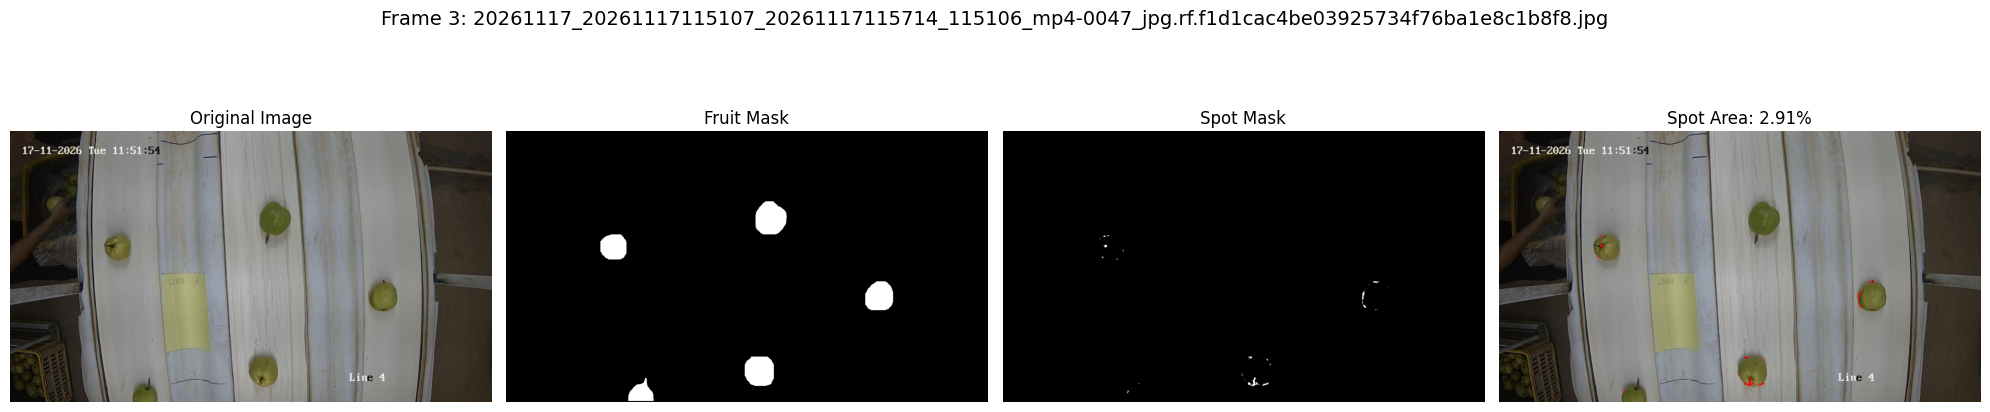

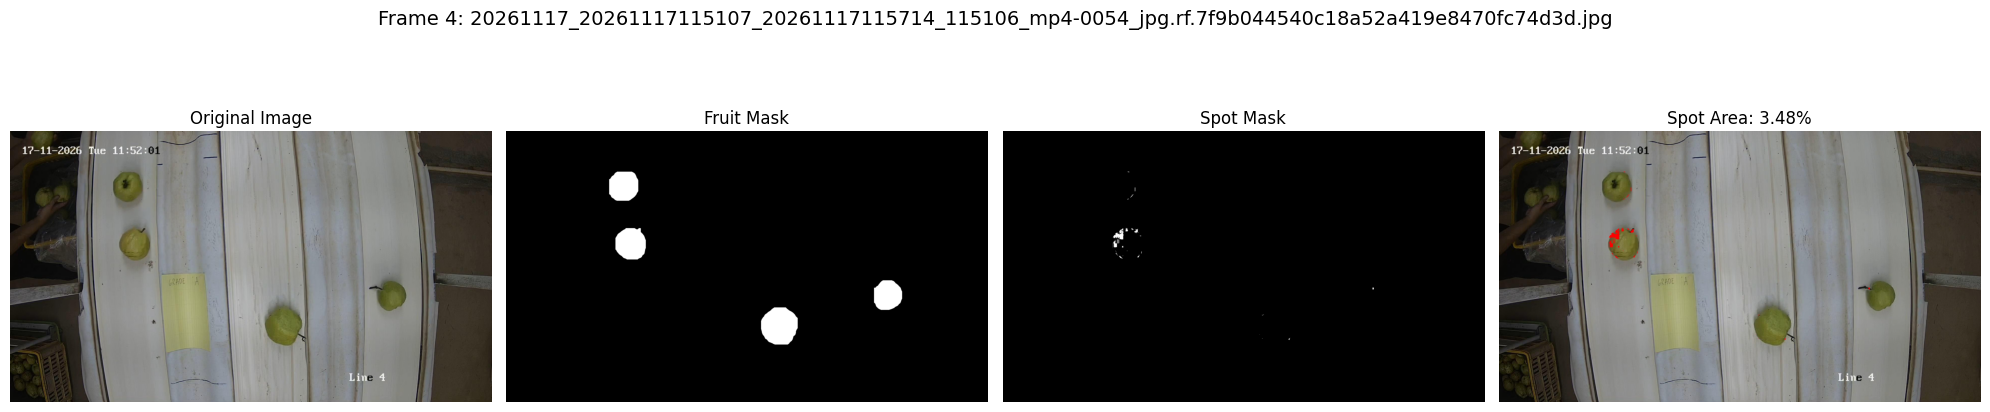

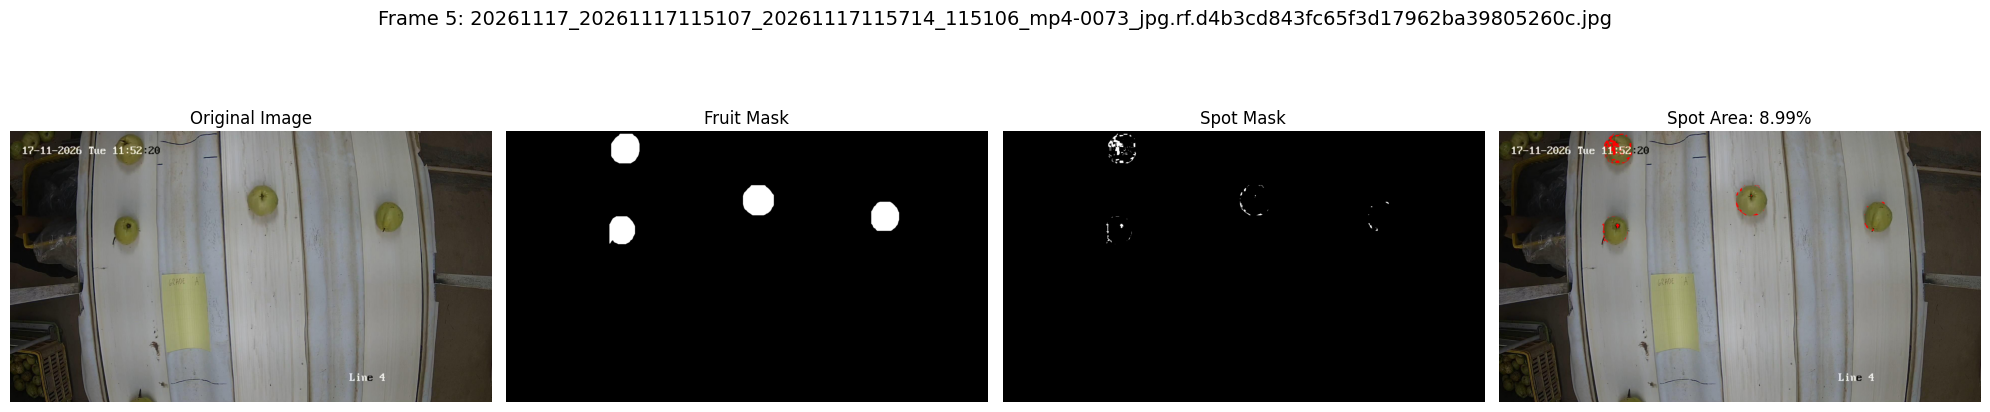

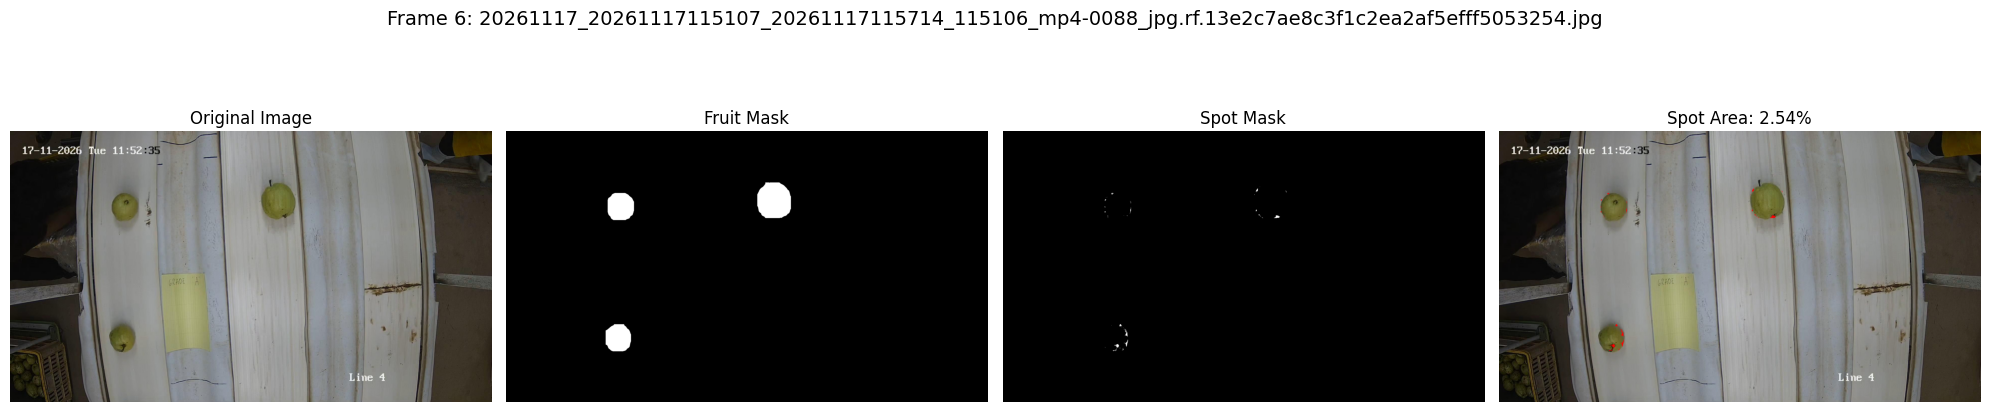

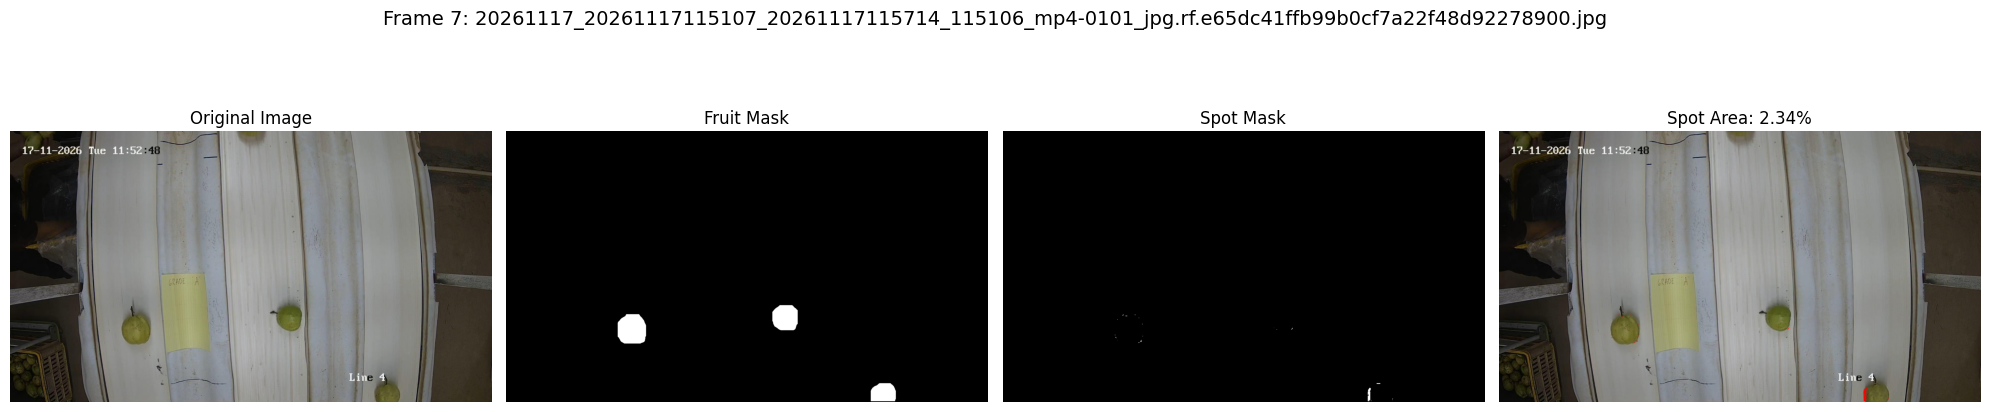

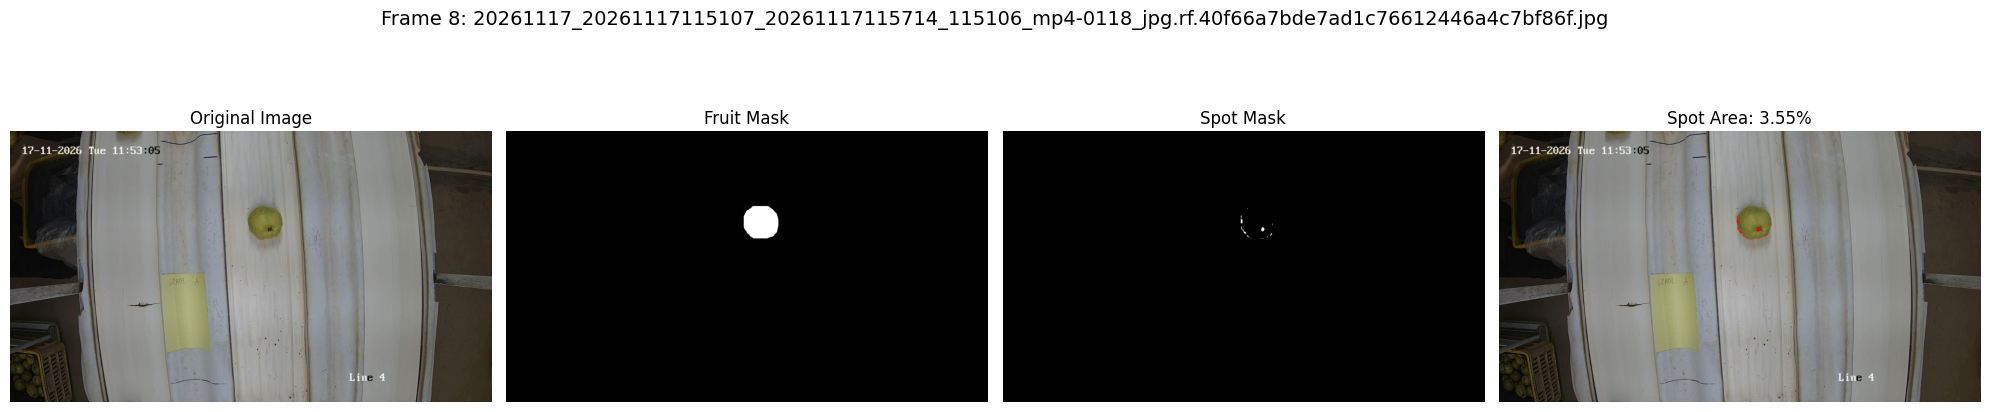

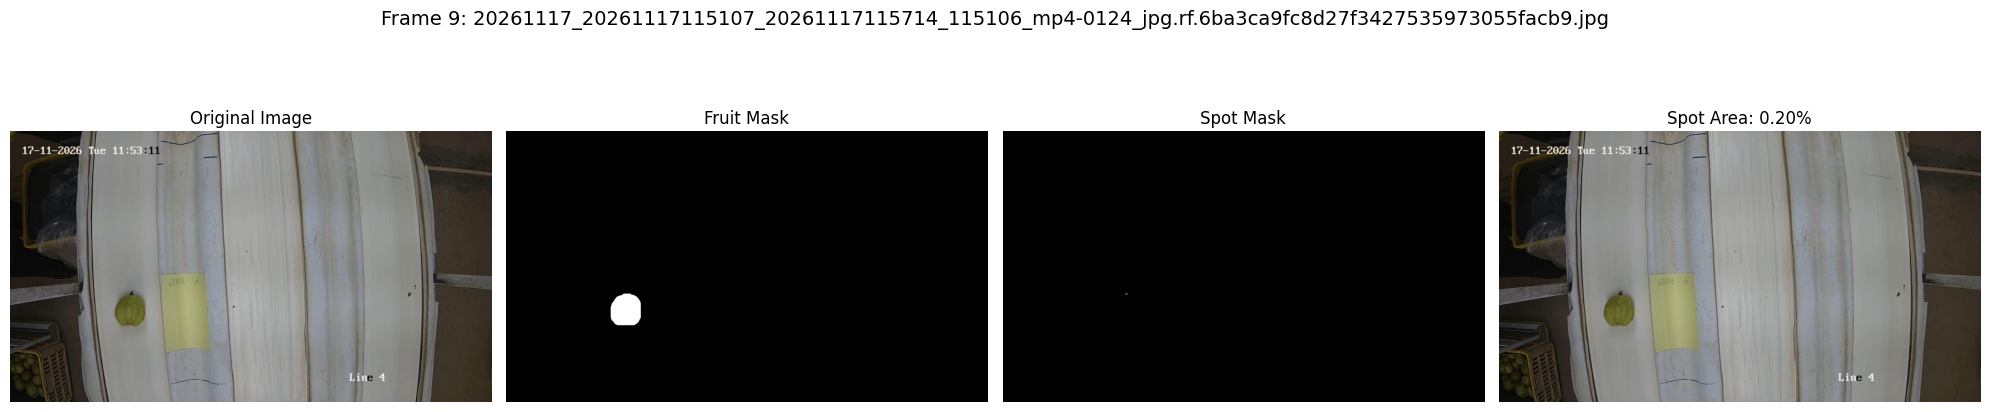

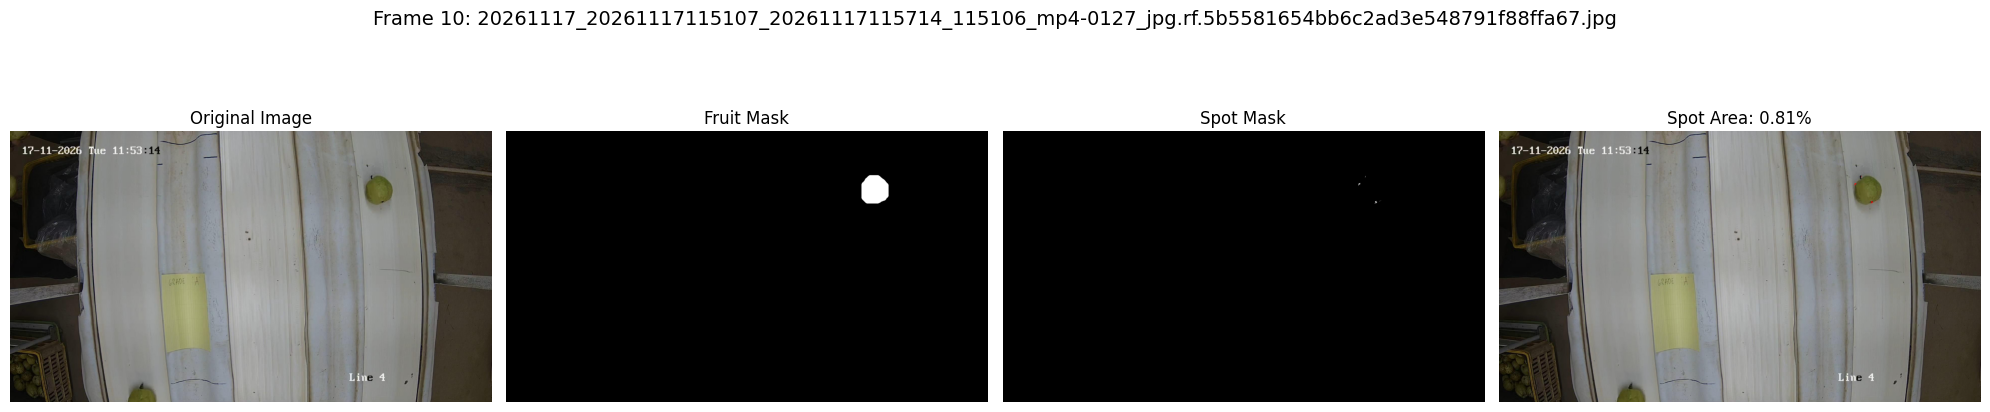

RINGKASAN HASIL


,Frame,Fruit Area (px),Spot Area (px),Spot Percentage (%)
0,20261117_20261117115107_20261117115714_115106_...,35466,487,1.37
1,20261117_20261117115107_20261117115714_115106_...,45067,1544,3.43
2,20261117_20261117115107_20261117115714_115106_...,50761,1477,2.91
3,20261117_20261117115107_20261117115714_115106_...,52666,1835,3.48
4,20261117_20261117115107_20261117115714_115106_...,44270,3982,8.99
5,20261117_20261117115107_20261117115714_115106_...,35383,898,2.54
6,20261117_20261117115107_20261117115714_115106_...,27040,632,2.34
7,20261117_20261117115107_20261117115714_115106_...,15172,539,3.55
8,20261117_20261117115107_20261117115714_115106_...,13066,26,0.20
9,20261117_20261117115107_20261117115714_115106_...,10330,84,0.81


In [15]:
def show_results(_=None):

    h_max = h_max_slider.value
    s_min = s_min_slider.value
    v_max = v_max_slider.value

    summary = []

    for i, data in enumerate(frame_data):

        image = data["image"]
        fruit_mask = data["fruit_mask"]

        # Konversi gambar ke HSV
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

        # Threshold bercak
        lower = np.array([0, s_min, 0])
        upper = np.array([h_max, 255, v_max])

        spot_mask = cv2.inRange(hsv, lower, upper)

        # Batasi bercak hanya di dalam mask buah
        spot_mask = cv2.bitwise_and(
            spot_mask,
            fruit_mask
        )

        # Hitung luas dalam piksel
        fruit_area = np.count_nonzero(fruit_mask)
        spot_area = np.count_nonzero(spot_mask)

        # Persentase bercak terhadap luas buah
        percentage = (
            (spot_area / fruit_area) * 100
            if fruit_area > 0 else 0
        )

        summary.append({
            "Frame": os.path.basename(data["path"]),
            "Fruit Area (px)": fruit_area,
            "Spot Area (px)": spot_area,
            "Spot Percentage (%)": round(percentage, 2)
        })

        # Konversi gambar asli ke RGB untuk matplotlib
        original_rgb = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        # Tampilkan empat visualisasi
        fig, axes = plt.subplots(1, 4, figsize=(20, 5))

        axes[0].imshow(original_rgb)
        axes[0].set_title("Original Image")

        axes[1].imshow(fruit_mask, cmap="gray")
        axes[1].set_title("Fruit Mask")

        axes[2].imshow(spot_mask, cmap="gray")
        axes[2].set_title("Spot Mask")

        # Overlay bercak pada gambar asli
        overlay = original_rgb.copy()
        overlay[spot_mask > 0] = [255, 0, 0]

        axes[3].imshow(overlay)
        axes[3].set_title(
            f"Spot Area: {percentage:.2f}%"
        )

        for ax in axes:
            ax.axis("off")

        plt.suptitle(
            f"Frame {i + 1}: {os.path.basename(data['path'])}",
            fontsize=14
        )

        plt.tight_layout()
        plt.show()

    # Tampilkan tabel hasil
    df = pd.DataFrame(summary)

    print("RINGKASAN HASIL")
    display(df)

    return df


# Tombol untuk menjalankan visualisasi
show_button = widgets.Button(
    description="Tampilkan hasil",
    button_style="success",
    icon="play"
)

output = widgets.interactive_output(
    lambda: None,
    {}
)

show_button.on_click(show_results)

display(show_button)